# IMS Bearing Data Analysis: From Raw Vibration to a Health Indicator

This notebook presents an end-to-end condition-monitoring analysis of the **IMS Bearing Dataset**.

The main idea is simple: a bearing produces vibration, and as it degrades, the vibration signal changes. Instead of looking at thousands of raw samples directly, we can extract a smaller set of features that describe the signal and then track how those features change over the life of the bearing.

The workflow is:

1. Load and inspect the raw vibration data.
2. Understand the signal in the **time domain**.
3. Learn the basic idea of the **FFT** using simple demo signals.
4. Understand spectral leakage and why a **Hann window** is useful.
5. Calculate theoretical bearing fault frequencies.
6. Compare healthy and near-failure signals.
7. Use **envelope analysis** to reveal the outer-race fault frequency.
8. Extract time-domain and frequency-domain features from every usable file.
9. Evaluate features using **monotonicity, trendability, and robustness**.
10. Compare the same features across three bearing failure cases.
11. Select a small common feature set.
12. Combine the selected features using PCA to create a health index.

The goal is not to build an unnecessarily complicated machine-learning model. The goal is to understand the physics behind the vibration signal and turn that understanding into a simple, interpretable degradation indicator.

## 1. Imports and project setup

We start with only the libraries needed for numerical work, plotting, signal processing, statistics, and PCA.

`Path` is used for file paths because it is cleaner than manually joining strings. The dataset location below is specific to the local machine used for this analysis, so it will need to be changed when the notebook is run elsewhere.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.signal import butter, hilbert, sosfiltfilt
from scipy.stats import kurtosis, pearsonr
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


# Dataset location
ROOT = Path("IMS")

FS = 20_000  # Sampling frequency in Hz

# Configuration for the three IMS experiments.
CASES = {
    "Case 1": {
        "folder": ROOT / "1st_test" / "1st_test",
        "column": 4,
        "fault": "BPFI",
    },
    "Case 2": {
        "folder": ROOT / "2nd_test" / "2nd_test",
        "column": 0,
        "fault": "BPFO",
    },
    "Case 3": {
        "folder": ROOT / "3rd_test" / "txt",
        "column": 2,
        "fault": "BPFO",
    },
}

## 2. Inspecting the dataset

Before doing any signal processing, it is useful to understand what one measurement file actually contains.

Each file contains simultaneous vibration measurements from multiple accelerometers. For the first demonstration we use **Bearing 1 from Case 2**, because the dataset documentation identifies this bearing as developing an outer-race fault.

The files are sorted so that their order represents the progression of the experiment.

In [2]:
case2_folder = CASES["Case 2"]["folder"]
case2_files = sorted(case2_folder.iterdir())

print(f"Number of files: {len(case2_files)}")
print(f"Type of file list: {type(case2_files)}")
print(f"First file: {case2_files[0]}")
print(f"Last file:  {case2_files[-1]}")

Number of files: 984
Type of file list: <class 'list'>
First file: IMS\2nd_test\2nd_test\2004.02.12.10.32.39
Last file:  IMS\2nd_test\2nd_test\2004.02.19.06.22.39


## 3. Load one raw vibration signal

`np.loadtxt()` reads the measurement file as a NumPy array.

We first inspect the complete array rather than immediately jumping into feature extraction. This is a small but important habit in data analysis: understand the shape and type of the data before deciding how to process it.

In [3]:
sample_data = np.loadtxt(case2_files[0])

print("Shape:", sample_data.shape)
print("Data type:", sample_data.dtype)

sample_data

Shape: (20480, 4)
Data type: float64


array([[-0.049, -0.071, -0.132, -0.01 ],
       [-0.042, -0.073, -0.007, -0.105],
       [ 0.015,  0.   ,  0.007,  0.   ],
       ...,
       [-0.012,  0.007,  0.056, -0.007],
       [-0.012,  0.093,  0.017, -0.044],
       [ 0.02 ,  0.076, -0.042, -0.029]], shape=(20480, 4))

The dataset has multiple columns because several accelerometers were recording at the same time. For the Case 2 analysis, column `0` corresponds to the vibration channel we are interested in.

In [4]:
bearing_1 = sample_data[:, CASES["Case 2"]["column"]]

print("Bearing 1 samples:", bearing_1.shape)

Bearing 1 samples: (20480,)


## 4. First look at the vibration signal in the time domain

The sampling frequency is 20 kHz, meaning that 20,000 measurements are recorded every second.

Here we plot only the first 0.1 seconds. Plotting the entire record at once would contain too many points to be visually useful, while a short section lets us see the actual vibration waveform.

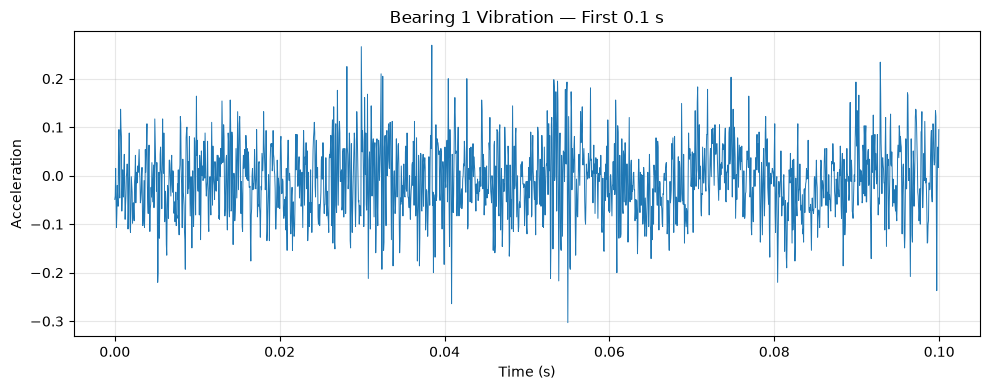

In [5]:
N_SHOW = 2_000
time = np.arange(N_SHOW) / FS

plt.figure(figsize=(10, 4))
plt.plot(time, bearing_1[:N_SHOW], linewidth=0.7)
plt.title("Bearing 1 Vibration — First 0.1 s")
plt.xlabel("Time (s)")
plt.ylabel("Acceleration")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Basic time-domain statistics

Before moving to the frequency domain, we can describe the signal using a few simple statistics.

- **Mean:** average value of the signal. A non-zero mean can represent a DC offset.
- **Minimum / maximum:** the largest negative and positive samples.
- **Standard deviation:** how much the signal varies around its mean.
- **RMS:** a common measure of vibration energy or overall signal magnitude.

These values are not enough to diagnose a bearing by themselves, but they provide a useful first baseline.

In [6]:
def rms(signal):
    return np.sqrt(np.mean(np.asarray(signal) ** 2))


print("Mean:", bearing_1.mean())
print("Minimum:", bearing_1.min())
print("Maximum:", bearing_1.max())
print("Standard deviation:", bearing_1.std())
print("RMS:", rms(bearing_1))

Mean: -0.01019599609375
Minimum: -0.386
Maximum: 0.454
Standard deviation: 0.07347493104305192
RMS: 0.07417899856512623


# 6. Understanding the FFT with simple signals

Before applying an FFT to real bearing data, it is worth seeing what the FFT does to signals whose frequencies we already know.

This avoids treating the FFT as a black box.

We start with a single sine wave at 100 Hz. Since we deliberately create the signal ourselves, we already know what frequency should appear in the spectrum.

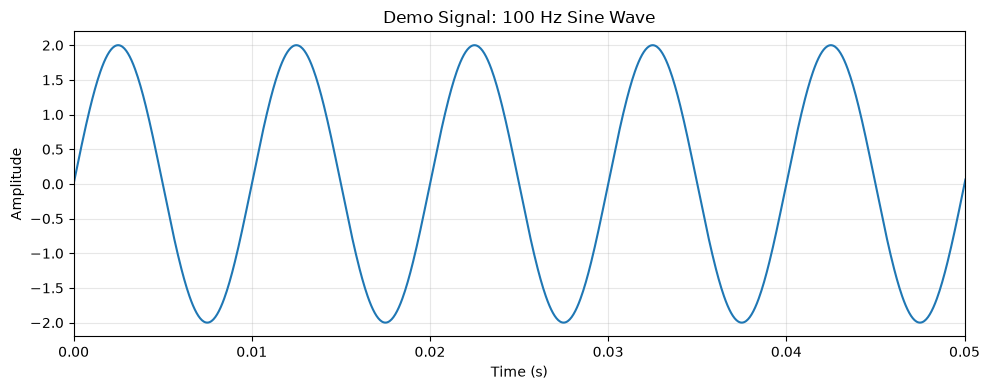

In [7]:
DEMO_N = 2_000
demo_time = np.arange(DEMO_N) / FS

demo_amplitude = 2.0
demo_frequency = 100.0

demo_signal = (
    demo_amplitude
    * np.sin(2 * np.pi * demo_frequency * demo_time)
)

plt.figure(figsize=(10, 4))
plt.plot(demo_time, demo_signal)
plt.xlim(0, 0.05)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Demo Signal: 100 Hz Sine Wave")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. FFT and frequency bins

The FFT converts the signal from the **time domain** into the **frequency domain**.

The important point is that an FFT does not give us an arbitrary continuous frequency axis. It gives values at discrete **frequency bins**.

For a record of `N` samples sampled at `FS`:

\[
\Delta f = \frac{FS}{N}
\]

With 2,000 samples at 20 kHz, the spacing is 10 Hz. Therefore 100 Hz lands exactly on a frequency bin, which makes this a particularly clean demonstration.

In [8]:
fft_result = np.fft.rfft(demo_signal)
freqs = np.fft.rfftfreq(DEMO_N, d=1 / FS)

print("Number of FFT values:", len(fft_result))
print("First few frequency bins:", freqs[:10])

Number of FFT values: 1001
First few frequency bins: [ 0. 10. 20. 30. 40. 50. 60. 70. 80. 90.]


`rfft()` is used because the original signal is real-valued. For a real signal, the negative-frequency side contains redundant information, so `rfft()` gives us only the non-negative frequencies.

The raw FFT magnitude is not yet the original sine-wave amplitude. We normalize it by the number of samples and account for the fact that the sine-wave energy is split between positive and negative frequencies.

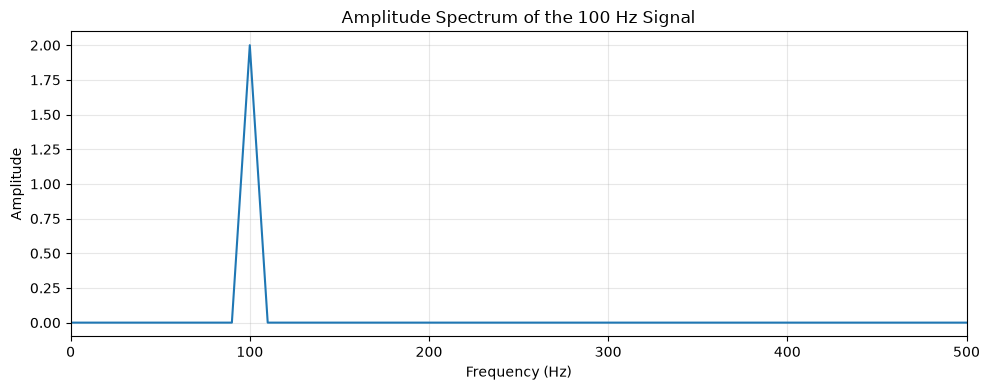

In [9]:
amplitude_spectrum = 2 * np.abs(fft_result) / DEMO_N

plt.figure(figsize=(10, 4))
plt.plot(freqs, amplitude_spectrum)
plt.xlim(0, 500)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Amplitude Spectrum of the 100 Hz Signal")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The large peak occurs at 100 Hz, exactly where expected.

For a sine wave whose frequency lands exactly on an FFT bin:

\[
|X_k| = \frac{A N}{2}
\]

So the raw magnitude depends on both the physical amplitude `A` and the number of samples `N`. The normalization above converts it into an amplitude-like quantity.

In [10]:
peak_index = np.argmax(np.abs(fft_result))

print("Peak bin:", peak_index)
print("Peak frequency:", freqs[peak_index], "Hz")
print("Raw FFT magnitude:", np.abs(fft_result[peak_index]))
print("Estimated amplitude:", amplitude_spectrum[peak_index])

Peak bin: 10
Peak frequency: 100.0 Hz
Raw FFT magnitude: 2000.0000000000005
Estimated amplitude: 2.0000000000000004


## 8. A signal containing multiple frequencies

Real vibration signals are rarely made from one clean sine wave. A machine can contain several vibration components at the same time.

Here we deliberately create a signal containing components at 50, 100, and 300 Hz with different amplitudes. The FFT should reveal all three components.

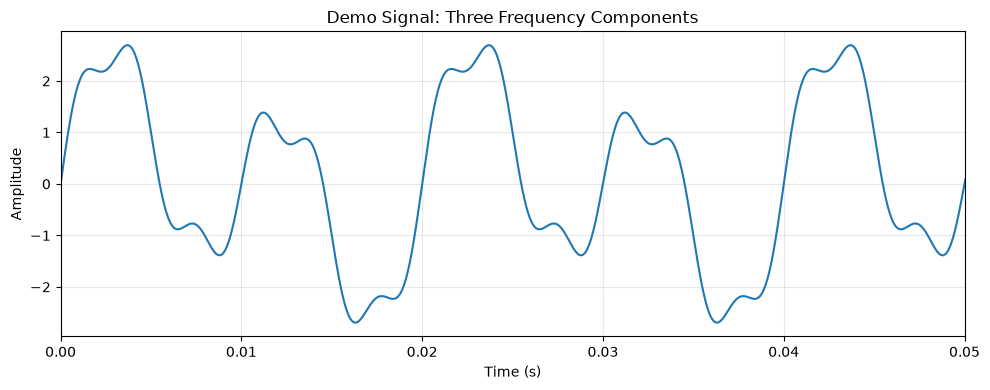

In [11]:
signal_50 = 1.0 * np.sin(2 * np.pi * 50 * demo_time)
signal_100 = 2.0 * np.sin(2 * np.pi * 100 * demo_time)
signal_300 = 0.5 * np.sin(2 * np.pi * 300 * demo_time)

mixed_signal = signal_50 + signal_100 + signal_300

plt.figure(figsize=(10, 4))
plt.plot(demo_time, mixed_signal)
plt.xlim(0, 0.05)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Demo Signal: Three Frequency Components")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

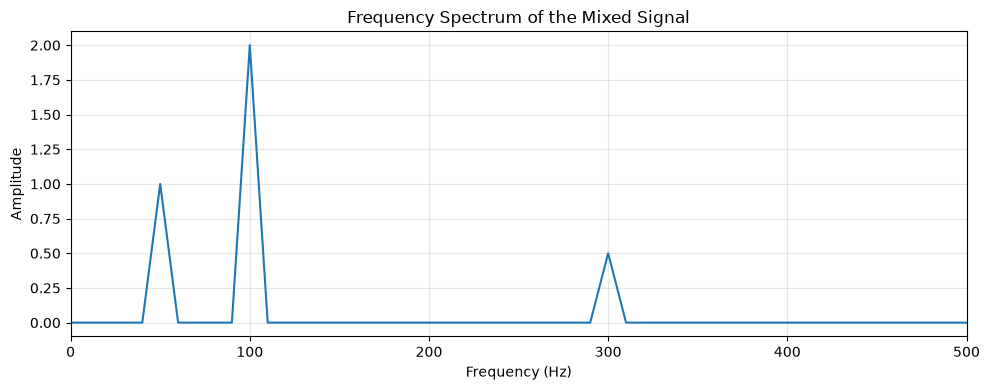

In [12]:
mixed_fft = np.fft.rfft(mixed_signal)
mixed_amplitude = 2 * np.abs(mixed_fft) / DEMO_N

plt.figure(figsize=(10, 4))
plt.plot(freqs, mixed_amplitude)
plt.xlim(0, 500)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Frequency Spectrum of the Mixed Signal")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The three peaks correspond to the three components we deliberately inserted.

This is the basic idea we will use later with the bearing data: instead of asking only **"how large is the vibration?"**, we can ask **"at which frequencies is the vibration energy concentrated?"**

For a particular target frequency, we can locate the nearest FFT bin using `argmin`.

In [13]:
for target_frequency in [50, 100, 300]:
    index = np.argmin(np.abs(freqs - target_frequency))
    print(
        f"{target_frequency:>3} Hz -> "
        f"nearest bin: {freqs[index]:.1f} Hz, "
        f"amplitude: {mixed_amplitude[index]:.2f}"
    )

 50 Hz -> nearest bin: 50.0 Hz, amplitude: 1.00
100 Hz -> nearest bin: 100.0 Hz, amplitude: 2.00
300 Hz -> nearest bin: 300.0 Hz, amplitude: 0.50


# 9. Spectral leakage

The previous examples were intentionally convenient: the signal frequencies landed exactly on FFT bins.

That will not always happen.

Suppose our signal contains 105 Hz. With a 10 Hz frequency resolution, there is no 105 Hz bin—only 100 Hz and 110 Hz. The FFT therefore cannot place all of the signal energy into one bin. Instead, energy spreads into nearby bins. This is called **spectral leakage**.

This matters in bearing analysis because we often care about a particular physical frequency, and we do not want the way we cut the signal into a finite window to create misleading spectral patterns.

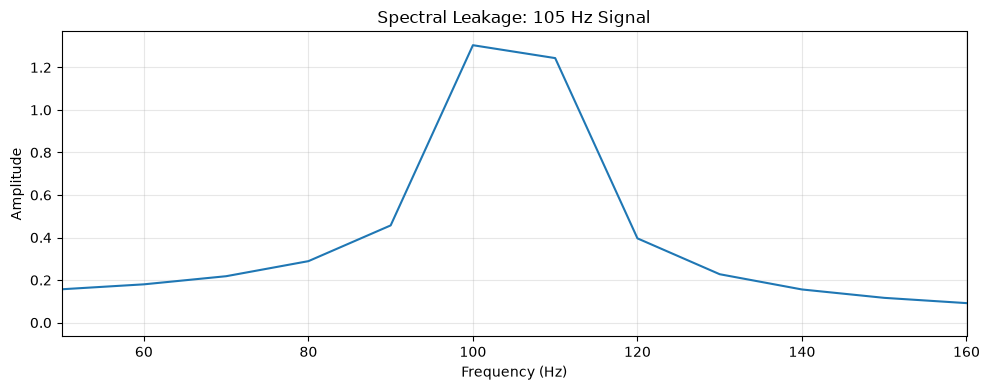

In [14]:
leak_frequency = 105.0
leak_signal = 2 * np.sin(
    2 * np.pi * leak_frequency * demo_time
)

leak_fft = np.fft.rfft(leak_signal)
leak_amplitude = 2 * np.abs(leak_fft) / DEMO_N

plt.figure(figsize=(10, 4))
plt.plot(freqs, leak_amplitude)
plt.xlim(50, 160)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Spectral Leakage: 105 Hz Signal")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Hann window

A finite measurement is effectively treated by the FFT as a repeating block. If the first and last samples do not line up smoothly, that artificial discontinuity creates extra frequency content.

A **Hann window** gradually reduces the signal toward zero at both ends of the recorded segment. This reduces the discontinuity and therefore reduces spectral leakage.

The trade-off is that windowing changes the signal amplitude, so when we estimate sinusoidal amplitude we compensate using the sum of the window values.

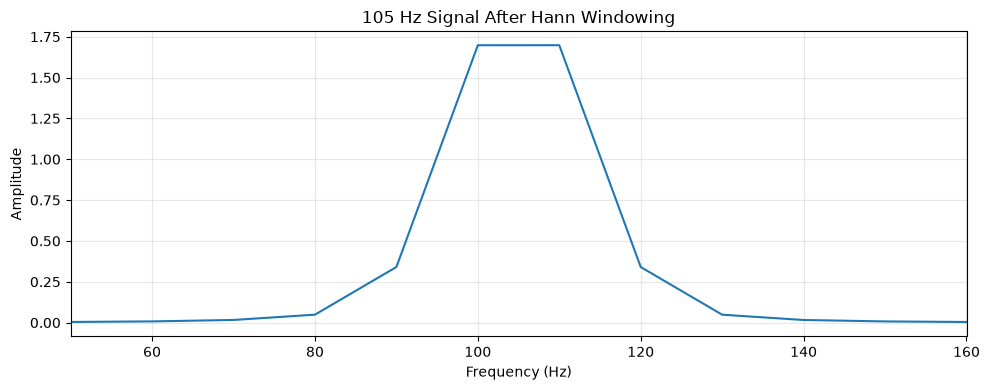

In [15]:
hann_window = np.hanning(DEMO_N)
windowed_signal = leak_signal * hann_window

windowed_fft = np.fft.rfft(windowed_signal)
windowed_amplitude = (
    2 * np.abs(windowed_fft) / hann_window.sum()
)

plt.figure(figsize=(10, 4))
plt.plot(freqs, windowed_amplitude)
plt.xlim(50, 160)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("105 Hz Signal After Hann Windowing")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

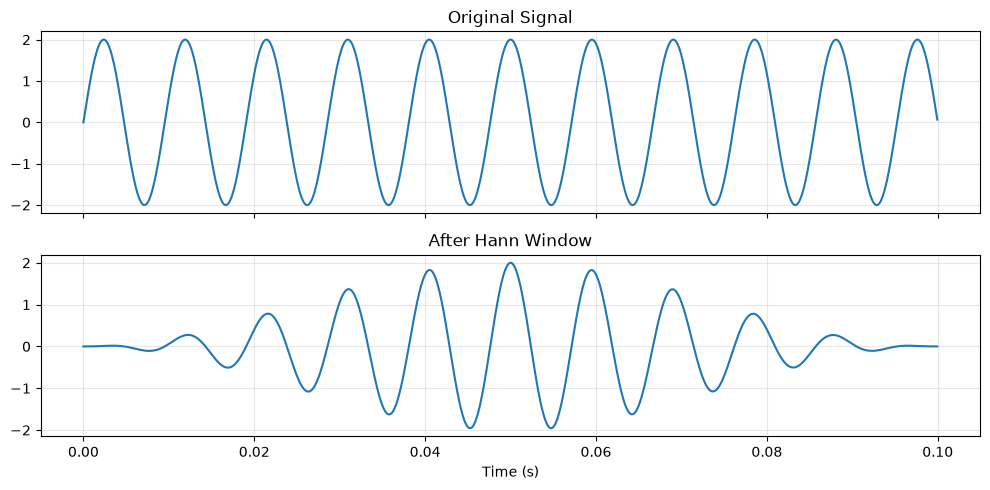

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

axes[0].plot(demo_time, leak_signal)
axes[0].set_title("Original Signal")

axes[1].plot(demo_time, windowed_signal)
axes[1].set_title("After Hann Window")
axes[1].set_xlabel("Time (s)")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 11. A reusable spectrum function

We have now repeated the same FFT steps several times. Rather than copying this logic throughout the notebook, we put it into one function.

This also makes the analysis easier to audit: whenever we calculate a spectrum later, we know exactly which preprocessing steps are being applied.

The function:
- removes the mean,
- applies a Hann window,
- calculates the one-sided FFT,
- creates the frequency axis,
- normalizes the amplitude.

In [17]:
def spectrum(signal, fs):
    # Remove DC offset before calculating the spectrum.
    signal = np.asarray(signal)
    signal = signal - np.mean(signal)

    n = len(signal)
    window = np.hanning(n)

    fft_values = np.fft.rfft(signal * window)
    frequencies = np.fft.rfftfreq(n, d=1 / fs)

    amplitude = 2 * np.abs(fft_values) / window.sum()

    return frequencies, amplitude

# 12. Inspecting the original bearing spectrum

Now we return to the real bearing signal.

The useful frequency range is limited by the Nyquist frequency, which is half the sampling rate. With a 20 kHz sampling frequency, the Nyquist frequency is 10 kHz.

We calculate these quantities before plotting the spectrum so we know what the measurement actually allows us to observe.

In [18]:
healthy_signal = np.loadtxt(
    case2_files[0]
)[:, CASES["Case 2"]["column"]]

healthy_n = len(healthy_signal)

print("Samples:", healthy_n)
print("Duration:", healthy_n / FS, "seconds")
print("Frequency resolution:", FS / healthy_n, "Hz")
print("Nyquist frequency:", FS / 2, "Hz")

Samples: 20480
Duration: 1.024 seconds
Frequency resolution: 0.9765625 Hz
Nyquist frequency: 10000.0 Hz


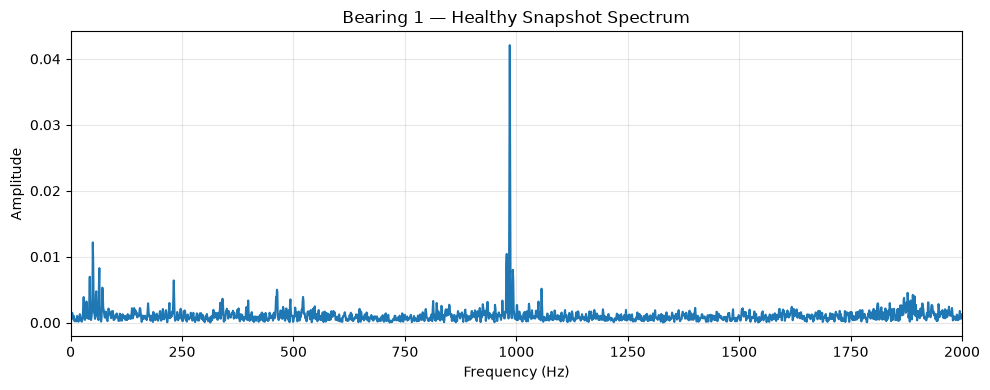

In [19]:
healthy_freq, healthy_amp = spectrum(healthy_signal, FS)

plt.figure(figsize=(10, 4))
plt.plot(healthy_freq, healthy_amp)
plt.xlim(0, 2_000)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Bearing 1 — Healthy Snapshot Spectrum")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

It is also useful to see what windowing changes. The goal is not to choose whichever spectrum looks "better", but to understand why the processing is being used.

The Hann spectrum should generally have lower leakage around strong components, at the cost of a wider main lobe.

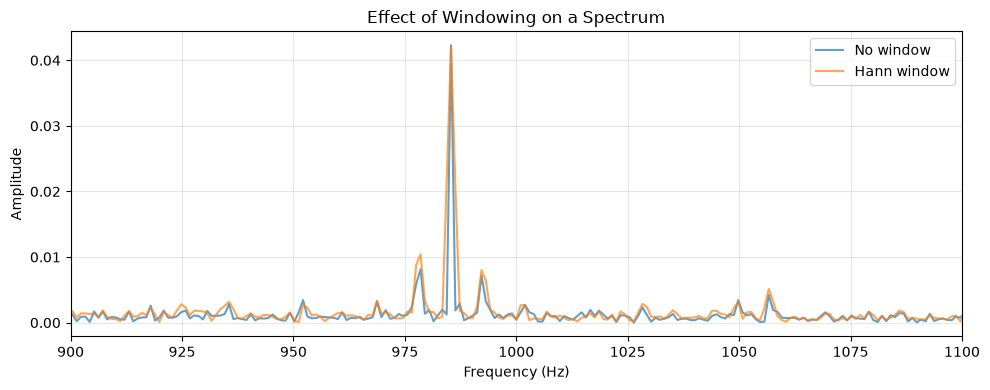

In [20]:
raw_freq = np.fft.rfftfreq(healthy_n, d=1 / FS)

centered_healthy = healthy_signal - healthy_signal.mean()
raw_amp = (
    2 * np.abs(np.fft.rfft(centered_healthy))
    / healthy_n
)

hann_window = np.hanning(healthy_n)
hann_fft = np.fft.rfft(centered_healthy * hann_window)
hann_amp = 2 * np.abs(hann_fft) / hann_window.sum()

plt.figure(figsize=(10, 4))
plt.plot(raw_freq, raw_amp, label="No window", alpha=0.7)
plt.plot(raw_freq, hann_amp, label="Hann window", alpha=0.7)

plt.xlim(900, 1_100)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Effect of Windowing on a Spectrum")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 13. A first look at degradation

The IMS dataset contains a sequence of measurements taken as the bearings operate toward failure.

A simple way to look for degradation is to compare a measurement from the beginning of the experiment with one near the end.

However, the dataset also contains a practical complication: some of the final files can contain extremely small values, which are not consistent with a genuine "healthy recovery". We therefore inspect RMS values before deciding which records to use.

In [21]:
last_signal = np.loadtxt(
    case2_files[-1]
)[:, CASES["Case 2"]["column"]]

print("First-file RMS:", rms(healthy_signal))
print("Last-file RMS: ", rms(last_signal))

print("\nLast five files:")
for file_path in case2_files[-5:]:
    signal = np.loadtxt(
        file_path
    )[:, CASES["Case 2"]["column"]]
    print(
        f"{file_path.name}: "
        f"RMS = {rms(signal):.6f}"
    )

First-file RMS: 0.07417899856512623
Last-file RMS:  0.001532732063383878

Last five files:
2004.02.19.05.42.39: RMS = 0.725001
2004.02.19.05.52.39: RMS = 0.462012
2004.02.19.06.02.39: RMS = 0.483835
2004.02.19.06.12.39: RMS = 0.002103
2004.02.19.06.22.39: RMS = 0.001533


The very small RMS values in the final records are much more consistent with a sensor/DAQ problem than with a bearing suddenly becoming almost vibration-free.

For this exploratory analysis, we use a simple RMS threshold to reject such dead-sensor records. This is deliberately transparent rather than hiding the decision inside a complicated anomaly detector.

In [22]:
for file_path in case2_files[-5:]:
    signal = np.loadtxt(
        file_path
    )[:, CASES["Case 2"]["column"]]

    print(
        f"{file_path.name}: "
        f"RMS = {rms(signal):.6f}"
    )

2004.02.19.05.42.39: RMS = 0.725001
2004.02.19.05.52.39: RMS = 0.462012
2004.02.19.06.02.39: RMS = 0.483835
2004.02.19.06.12.39: RMS = 0.002103
2004.02.19.06.22.39: RMS = 0.001533


For Case 2, the third-from-last record is used as a representative near-failure measurement after excluding the two extremely small records.

This is an exploratory visualization. We are not claiming that this file is the exact physical instant of failure.

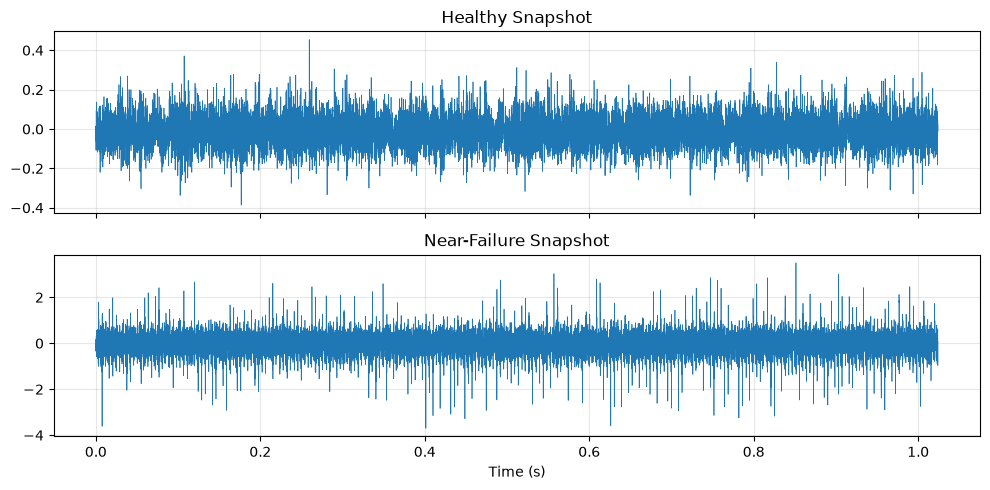

In [23]:
near_failure_signal = np.loadtxt(
    case2_files[-3]
)[:, CASES["Case 2"]["column"]]

plot_time = np.arange(len(healthy_signal)) / FS

fig, axes = plt.subplots(
    2, 1, figsize=(10, 5), sharex=True
)

axes[0].plot(
    plot_time,
    healthy_signal,
    linewidth=0.5,
)
axes[0].set_title("Healthy Snapshot")

axes[1].plot(
    plot_time,
    near_failure_signal,
    linewidth=0.5,
)
axes[1].set_title("Near-Failure Snapshot")
axes[1].set_xlabel("Time (s)")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 14. Time-domain vibration features

A single RMS value does not capture everything about a vibration signal. We therefore calculate four simple time-domain features:

- **RMS:** overall vibration magnitude.
- **Peak:** largest absolute acceleration.
- **Crest factor:** peak divided by RMS. It can increase when sharp impacts appear.
- **Kurtosis:** a measure of how strongly the distribution is influenced by extreme values. Bearing defects can produce impulsive events, which can increase kurtosis.

These features are useful because a damaged bearing often produces impacts rather than simply increasing the entire waveform uniformly.

In [24]:
def time_features(signal):
    signal = np.asarray(signal)

    rms_value = rms(signal)
    peak_value = np.max(np.abs(signal))
    crest_factor = peak_value / rms_value
    kurtosis_value = kurtosis(signal, fisher=False)

    return {
        "RMS": rms_value,
        "Peak": peak_value,
        "Crest": crest_factor,
        "Kurtosis": kurtosis_value,
    }


healthy_time_features = time_features(healthy_signal)
failure_time_features = time_features(near_failure_signal)

print("Healthy:", healthy_time_features)
print("Near failure:", failure_time_features)

print(
    "\nRMS increase factor:",
    rms(near_failure_signal) / rms(healthy_signal),
)

Healthy: {'RMS': np.float64(0.07417899856512623), 'Peak': np.float64(0.454), 'Crest': np.float64(6.120330670161392), 'Kurtosis': np.float64(3.6287626426442556)}
Near failure: {'RMS': np.float64(0.4838353953514789), 'Peak': np.float64(3.696), 'Crest': np.float64(7.6389615879902015), 'Kurtosis': np.float64(7.891755233183495)}

RMS increase factor: 6.522538787399381


# 15. Bearing defect frequencies

Bearing faults have characteristic frequencies determined by the bearing geometry and shaft speed.

The four standard frequencies used here are:

- **BPFO:** Ball Pass Frequency, Outer race
- **BPFI:** Ball Pass Frequency, Inner race
- **BSF:** Ball Spin Frequency
- **FTF:** Fundamental Train Frequency

The IMS README gives the bearing geometry for the Rexnord ZA-2115 bearing. We combine those dimensions with the shaft speed to calculate the theoretical fault frequencies.

This is where signal processing connects back to engineering physics: the frequencies are not arbitrary features chosen because they correlate with failure. They come from the mechanics of the bearing.

In [25]:
SHAFT_RPM = 2_000
ROLLING_ELEMENTS = 16
ROLLING_DIAMETER_IN = 0.331
PITCH_DIAMETER_IN = 2.815
CONTACT_ANGLE_DEG = 15.17

shaft_frequency = SHAFT_RPM / 60
contact_angle = np.deg2rad(CONTACT_ANGLE_DEG)

geometry_ratio = (
    ROLLING_DIAMETER_IN / PITCH_DIAMETER_IN
) * np.cos(contact_angle)

BPFO = (
    ROLLING_ELEMENTS / 2
    * shaft_frequency
    * (1 - geometry_ratio)
)

BPFI = (
    ROLLING_ELEMENTS / 2
    * shaft_frequency
    * (1 + geometry_ratio)
)

BSF = (
    PITCH_DIAMETER_IN
    / (2 * ROLLING_DIAMETER_IN)
    * shaft_frequency
    * (1 - geometry_ratio**2)
)

FTF = (
    shaft_frequency / 2
    * (1 - geometry_ratio)
)

FAULT_FREQUENCIES = {
    "BPFO": BPFO,
    "BPFI": BPFI,
    "BSF": BSF,
    "FTF": FTF,
}

print(f"Shaft frequency: {shaft_frequency:.2f} Hz")

for name, value in FAULT_FREQUENCIES.items():
    print(f"{name}: {value:.2f} Hz")

Shaft frequency: 33.33 Hz
BPFO: 236.40 Hz
BPFI: 296.93 Hz
BSF: 139.92 Hz
FTF: 14.78 Hz


The dataset documentation identifies the Case 2 bearing as developing an **outer-race fault**.

Therefore our engineering hypothesis is:

> If an outer-race defect is developing, vibration energy associated with impacts repeating at approximately the BPFO should become more noticeable.

For this bearing and operating condition, the theoretical BPFO is around 236 Hz.

The next step is to test this hypothesis against the measured signal.

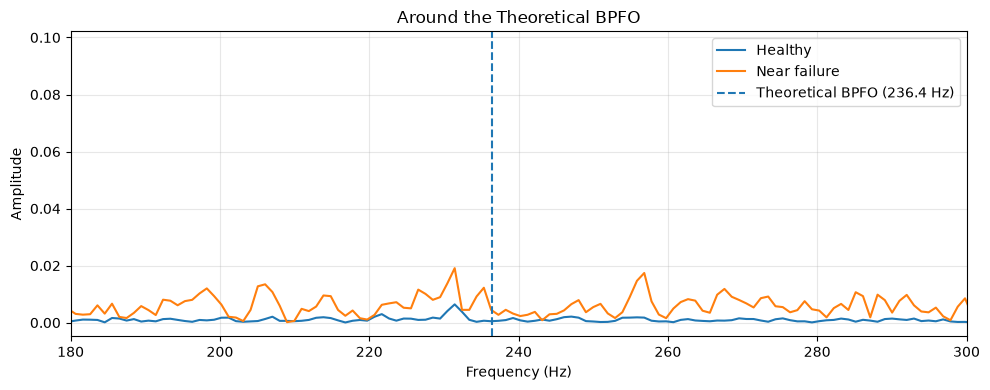

In [26]:
healthy_freq, healthy_amp = spectrum(
    healthy_signal,
    FS,
)

failure_freq, failure_amp = spectrum(
    near_failure_signal,
    FS,
)

plt.figure(figsize=(10, 4))

plt.plot(
    healthy_freq,
    healthy_amp,
    label="Healthy",
)

plt.plot(
    failure_freq,
    failure_amp,
    label="Near failure",
)

plt.axvline(
    BPFO,
    linestyle="--",
    label=f"Theoretical BPFO ({BPFO:.1f} Hz)",
)

plt.xlim(180, 300)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Around the Theoretical BPFO")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

There is an important lesson here: **a bearing defect frequency does not necessarily appear as a large, clean peak in the raw acceleration spectrum.**

Bearing defects often create short-duration impacts. Those impacts excite higher-frequency structural resonances, and the defect frequency appears in the *repetition rate* of those impacts.

This motivates **envelope analysis**.

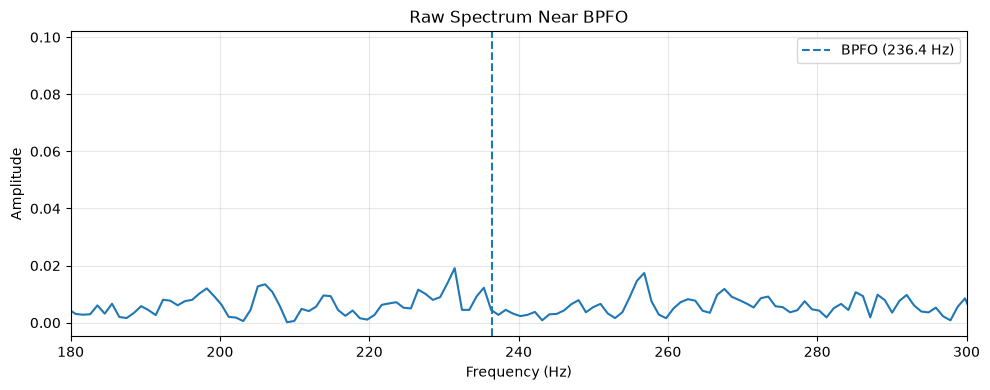

In [27]:
plt.figure(figsize=(10, 4))

plt.plot(
    failure_freq,
    failure_amp,
)

plt.axvline(
    BPFO,
    linestyle="--",
    label=f"BPFO ({BPFO:.1f} Hz)",
)

plt.xlim(180, 300)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Raw Spectrum Near BPFO")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 16. Envelope analysis

The basic idea is:

1. Select a higher-frequency band where bearing impacts excite vibration strongly.
2. Extract the amplitude envelope of that filtered signal.
3. Perform an FFT on the envelope.
4. Look for repetition frequencies such as BPFO or BPFI.

The band used here is **2–6 kHz**. This is a practical starting band for this dataset, not a universal rule for every bearing or machine.

We use a Butterworth band-pass filter implemented as second-order sections (`sos`). The SOS form is numerically safer for higher-order filters.

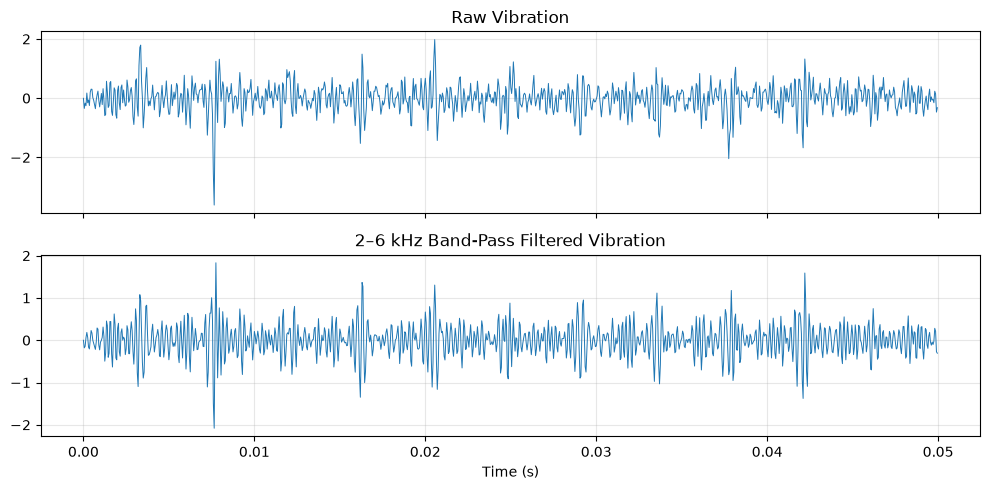

In [28]:
def bandpass_filter(
    signal,
    fs,
    band=(2_000, 6_000),
    order=4,
):
    sos = butter(
        order,
        band,
        btype="bandpass",
        fs=fs,
        output="sos",
    )

    return sosfiltfilt(sos, signal)


filtered_failure = bandpass_filter(
    near_failure_signal,
    FS,
    band=(2_000, 6_000),
)

n_show = int(0.05 * FS)
short_time = np.arange(n_show) / FS

fig, axes = plt.subplots(
    2, 1, figsize=(10, 5), sharex=True
)

axes[0].plot(
    short_time,
    near_failure_signal[:n_show],
    linewidth=0.7,
)
axes[0].set_title("Raw Vibration")

axes[1].plot(
    short_time,
    filtered_failure[:n_show],
    linewidth=0.7,
)
axes[1].set_title("2–6 kHz Band-Pass Filtered Vibration")
axes[1].set_xlabel("Time (s)")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Next we use the **Hilbert transform** to obtain the analytic signal. Its magnitude gives us an estimate of the instantaneous amplitude envelope.

The envelope lets us focus on *when the high-frequency impacts occur* rather than on the individual high-frequency oscillations themselves.

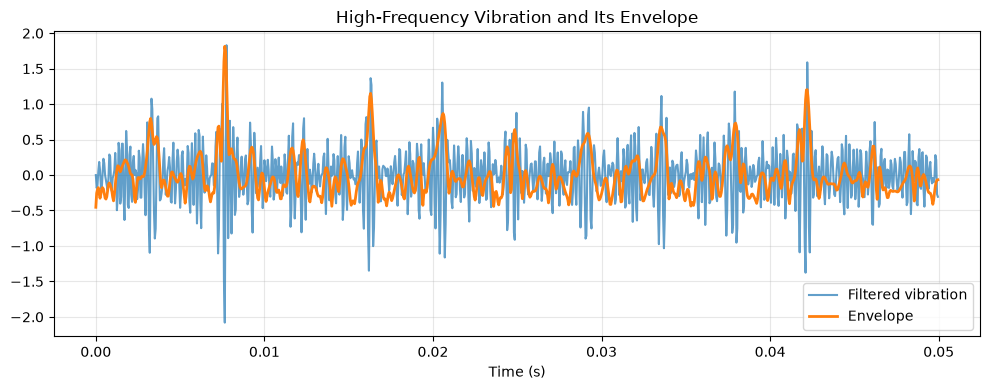

In [29]:
def envelope(
    signal,
    fs,
    band=(2_000, 6_000),
):
    filtered = bandpass_filter(
        signal,
        fs,
        band=band,
    )

    analytic_signal = hilbert(filtered)
    env = np.abs(analytic_signal)

    # Remove the envelope's average level so the later FFT
    # does not contain a dominant DC component.
    return env - env.mean()


failure_envelope = envelope(
    near_failure_signal,
    FS,
)

plt.figure(figsize=(10, 4))

plt.plot(
    short_time,
    filtered_failure[:n_show],
    label="Filtered vibration",
    alpha=0.7,
)

plt.plot(
    short_time,
    failure_envelope[:n_show],
    label="Envelope",
    linewidth=2,
)

plt.xlabel("Time (s)")
plt.title("High-Frequency Vibration and Its Envelope")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The final step is simply another FFT—but this time we apply it to the **envelope** instead of the original acceleration.

If the high-frequency impacts repeat at the BPFO rate, the envelope spectrum should contain a component near BPFO.

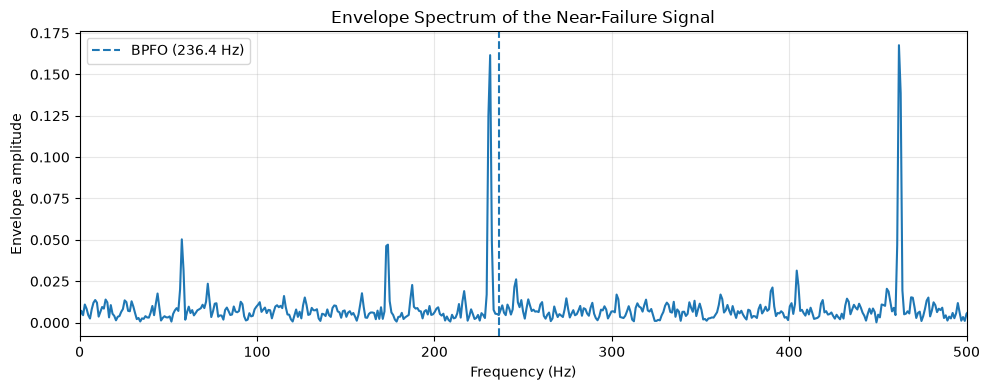

In [30]:
envelope_freq, envelope_amp = spectrum(
    failure_envelope,
    FS,
)

plt.figure(figsize=(10, 4))
plt.plot(envelope_freq, envelope_amp)

plt.axvline(
    BPFO,
    linestyle="--",
    label=f"BPFO ({BPFO:.1f} Hz)",
)

plt.xlim(0, 500)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Envelope amplitude")
plt.title("Envelope Spectrum of the Near-Failure Signal")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The peak around BPFO provides evidence that the vibration impacts are repeating at a rate consistent with an outer-race defect.

This is stronger evidence than simply observing that the overall RMS increased: we have a feature tied to the **known physical fault mechanism**.

We can now turn this visual observation into numerical features.

# 17. Extracting frequency-domain fault features

For each theoretical bearing frequency, we examine a small ±10 Hz region around the expected value.

Two features are extracted:

- **Peak:** the tallest spectral line in the region.
- **RMS:** the overall magnitude of the spectrum within the region.

The peak feature asks, *"What is the strongest line near this fault frequency?"*

The RMS feature asks, *"How much spectral activity is present across this whole region?"*

Using a small band rather than demanding one exact FFT bin also makes the feature less sensitive to small frequency shifts and finite frequency resolution.

In [31]:
def fault_frequency_features(
    signal,
    fs,
    fault_frequencies,
    band_half_width=10,
):
    env = envelope(signal, fs)

    frequencies, amplitude = spectrum(
        env,
        fs,
    )

    features = {}

    for name, target_frequency in fault_frequencies.items():
        mask = (
            (frequencies >= target_frequency - band_half_width)
            & (frequencies <= target_frequency + band_half_width)
        )

        band = amplitude[mask]

        features[name] = np.max(band)
        features[f"{name}_rms"] = np.sqrt(
            np.mean(band**2)
        )

    return features


case2_fault_features = fault_frequency_features(
    near_failure_signal,
    FS,
    FAULT_FREQUENCIES,
)

for name, value in case2_fault_features.items():
    print(f"{name:10s}: {value:.6f}")

BPFO      : 0.161562
BPFO_rms  : 0.046916
BPFI      : 0.016962
BPFI_rms  : 0.007703
BSF       : 0.010380
BSF_rms   : 0.006766
FTF       : 0.013940
FTF_rms   : 0.008273


# 18. Putting the feature extraction into one function

We now have all the pieces needed to process a complete vibration record.

The final feature set contains:

**Time domain**
- RMS
- Peak
- Crest
- Kurtosis

**Envelope-frequency domain**
- BPFO
- BPFI
- BSF
- FTF
- and an RMS version of each

That gives us 12 features per measurement file.

Keeping this logic in one function is important because the exact same processing must be applied to every file. Otherwise, it would be very easy to accidentally process different files in slightly different ways.

In [32]:
def extract_features(
    signal,
    fs,
    fault_frequencies,
):
    features = time_features(signal)

    features.update(
        fault_frequency_features(
            signal,
            fs,
            fault_frequencies,
        )
    )

    return features

# 19. Process all files for Case 2

We can now loop through the complete Case 2 experiment.

The RMS threshold is used to skip the extremely small records identified earlier as likely sensor/DAQ failures. We preserve the original `file_idx` rather than renumbering the remaining records, because the original file order represents time in the experiment.

This distinction matters: if file 500 is removed, file 501 should still be identified as file index 501 rather than pretending it was measurement 500.

In [33]:
def build_feature_dataframe(
    folder,
    column,
    fs,
    fault_frequencies,
    rms_threshold=0.02,
):
    file_paths = sorted(folder.iterdir())
    rows = []

    for file_idx, file_path in enumerate(file_paths):
        signal = np.loadtxt(file_path)[:, column]

        if rms(signal) < rms_threshold:
            continue

        features = extract_features(
            signal,
            fs,
            fault_frequencies,
        )

        rows.append({
            "file_idx": file_idx,
            **features,
        })

    return pd.DataFrame(rows)


case2_features = build_feature_dataframe(
    folder=CASES["Case 2"]["folder"],
    column=CASES["Case 2"]["column"],
    fs=FS,
    fault_frequencies=FAULT_FREQUENCIES,
)

case2_features.to_csv(
    "Case_2_features.csv",
    index=False,
)

print(
    f"Usable Case 2 records: "
    f"{len(case2_features)}"
)
print("Feature extraction complete.")

Usable Case 2 records: 982
Feature extraction complete.


## 20. Life curves

A **life curve** shows how a feature changes as the bearing progresses through the experiment.

RMS tells us about overall vibration severity, while BPFO and BPFO RMS are more closely connected to the known outer-race fault.

A useful health indicator should generally become more informative as degradation progresses, rather than simply fluctuating randomly.

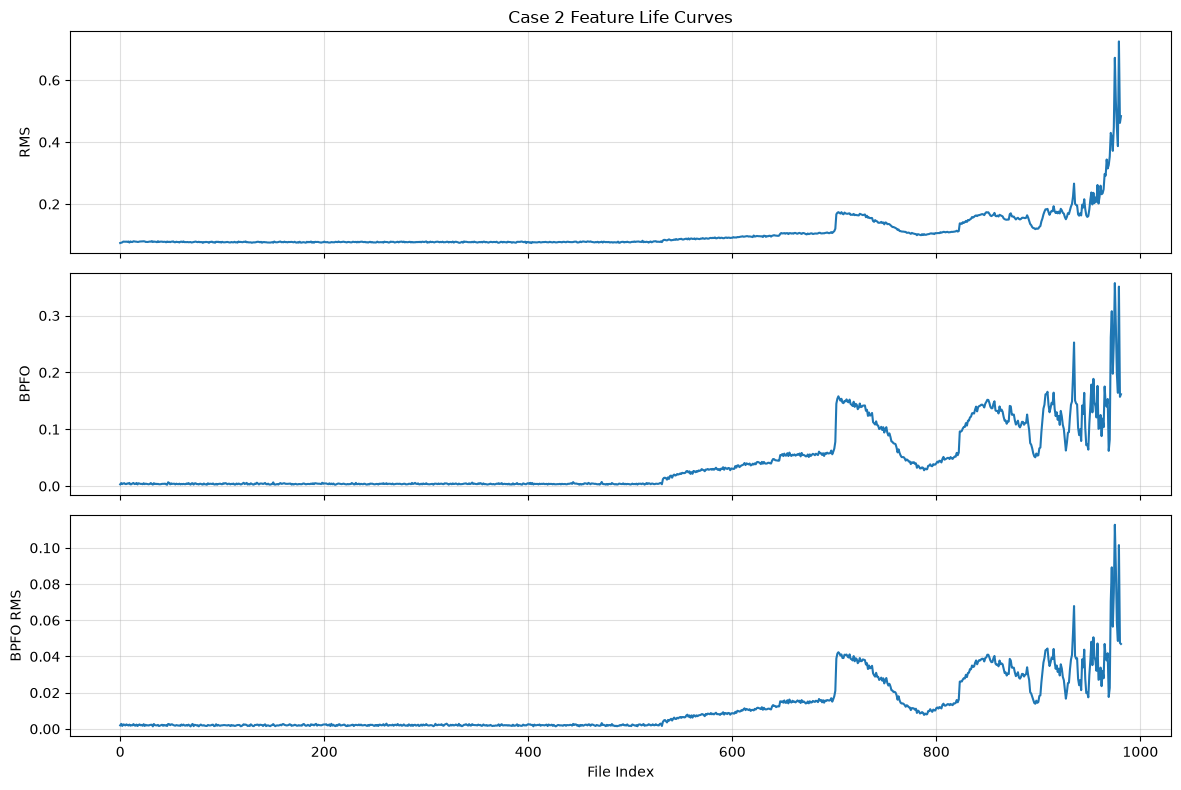

In [34]:
fig, axes = plt.subplots(
    3, 1, figsize=(12, 8), sharex=True
)

axes[0].plot(
    case2_features["file_idx"],
    case2_features["RMS"],
)
axes[0].set_ylabel("RMS")
axes[0].set_title("Case 2 Feature Life Curves")
axes[0].grid(alpha=0.4)

axes[1].plot(
    case2_features["file_idx"],
    case2_features["BPFO"],
)
axes[1].set_ylabel("BPFO")
axes[1].grid(alpha=0.4)

axes[2].plot(
    case2_features["file_idx"],
    case2_features["BPFO_rms"],
)
axes[2].set_ylabel("BPFO RMS")
axes[2].set_xlabel("File Index")
axes[2].grid(alpha=0.4)

plt.tight_layout()
plt.show()

# 21. How do we decide which feature is a good health indicator?

Looking at plots is useful, but it is subjective. We therefore score each feature using three simple properties:

### Monotonicity
Does the feature mostly move in one direction as the bearing degrades?

### Trendability
Does the feature have a clear relationship with time?

### Robustness
Is the underlying trend reasonably stable instead of being dominated by noise?

No single metric is perfect. We use their average as a simple overall score.

The moving average below is used only to estimate the smooth trend. The original feature values are still retained for the robustness calculation.

In [35]:
METRIC_WINDOW = 21


def split_trend(
    values,
    window=METRIC_WINDOW,
):
    values = np.asarray(values)

    trend = (
        pd.Series(values)
        .rolling(
            window,
            center=True,
            min_periods=1,
        )
        .mean()
        .to_numpy()
    )

    residual = values - trend

    return trend, residual

## Monotonicity

For each consecutive pair of points in the smoothed trend, we check whether the feature moved upward or downward.

If almost all movements have the same direction, the monotonicity score approaches 1. If upward and downward movements are balanced, the score approaches 0.

This is intentionally a simple metric. It captures the idea we care about: degradation indicators should not repeatedly reverse direction.

In [36]:
def monotonicity(trend):
    differences = np.diff(trend)

    if len(differences) == 0:
        return np.nan

    upward = np.sum(differences > 0)
    downward = np.sum(differences < 0)

    return abs(upward - downward) / len(differences)

## Trendability

Trendability is measured here using the absolute Pearson correlation between the feature trend and a simple time index.

A value close to 1 means the trend has a strong approximately linear relationship with time. We use the absolute value because either an increasing or decreasing health indicator can be meaningful.

In [37]:
def trendability(trend):
    trend = np.asarray(trend)

    if len(trend) < 2 or np.std(trend) == 0:
        return 0.0

    time_index = np.arange(len(trend))
    correlation, _ = pearsonr(
        time_index,
        trend,
    )

    return abs(correlation)

## Robustness

The residual is the difference between the original feature and its smooth trend.

The idea behind the robustness score is simple: if the residual is small relative to the signal itself, the feature is less noisy around its trend.

A small epsilon is included in the denominator so that a feature value of exactly zero cannot cause a division-by-zero error.

In [38]:
def robustness(
    values,
    residual,
    epsilon=1e-12,
):
    values = np.asarray(values)
    residual = np.asarray(residual)

    relative_error = (
        np.abs(residual)
        / (np.abs(values) + epsilon)
    )

    return np.mean(
        np.exp(-relative_error)
    )

## Combine the three metrics

The following function applies all three metrics to every feature column.

The resulting table lets us compare features using the same criteria instead of relying only on visual inspection.

In [39]:
def score_features(feature_df):
    results = []

    feature_names = [
        column
        for column in feature_df.columns
        if column != "file_idx"
    ]

    for feature in feature_names:
        values = feature_df[feature].to_numpy()
        trend, residual = split_trend(values)

        monotonicity_score = monotonicity(trend)
        trendability_score = trendability(trend)
        robustness_score = robustness(
            values,
            residual,
        )

        average_score = np.mean([
            monotonicity_score,
            trendability_score,
            robustness_score,
        ])

        results.append({
            "Feature": feature,
            "Monotonicity": monotonicity_score,
            "Trendability": trendability_score,
            "Robustness": robustness_score,
            "Average": average_score,
        })

    return (
        pd.DataFrame(results)
        .sort_values(
            "Average",
            ascending=False,
        )
        .reset_index(drop=True)
    )


case2_scores = score_features(case2_features)

print("Feature ranking for Case 2:")
print(case2_scores.round(3))

Feature ranking for Case 2:
     Feature  Monotonicity  Trendability  Robustness  Average
0   BPFO_rms         0.148         0.810       0.893    0.617
1       BPFO         0.142         0.821       0.877    0.613
2        RMS         0.172         0.680       0.978    0.610
3   Kurtosis         0.064         0.644       0.967    0.558
4   BPFI_rms         0.093         0.618       0.886    0.532
5       Peak         0.047         0.583       0.925    0.518
6    BSF_rms         0.070         0.584       0.883    0.513
7       BPFI         0.054         0.606       0.856    0.505
8        BSF         0.044         0.563       0.858    0.488
9    FTF_rms         0.052         0.463       0.877    0.464
10       FTF         0.042         0.303       0.810    0.385
11     Crest         0.015         0.148       0.934    0.366


# 22. Compare the three IMS failure cases

A feature that works well for one bearing failure is not automatically a good general health indicator.

For example, BPFO should be particularly useful for an outer-race fault, while BPFI should be more relevant for an inner-race fault. But a general degradation indicator should ideally remain useful across different failure cases.

We therefore apply the exact same feature extraction and scoring procedure to all three experiments.

The CSV files are saved so that the expensive signal-processing step does not need to be repeated every time the notebook is opened.

In [40]:
def process_all_cases(
    cases,
    fs,
    fault_frequencies,
    rms_threshold=0.02,
):
    frames = {}
    score_tables = {}

    for case_name, info in cases.items():
        print(f"Processing {case_name}...")

        df = build_feature_dataframe(
            folder=info["folder"],
            column=info["column"],
            fs=fs,
            fault_frequencies=fault_frequencies,
            rms_threshold=rms_threshold,
        )

        frames[case_name] = df
        score_tables[case_name] = score_features(df)

        output_name = (
            f"{case_name.replace(' ', '_')}_features.csv"
        )

        df.to_csv(
            output_name,
            index=False,
        )

        print(
            f"  Usable records: {len(df)}"
            f" | saved to {output_name}"
        )

    return frames, score_tables


frames, score_tables = process_all_cases(
    CASES,
    FS,
    FAULT_FREQUENCIES,
)

print("\nAll cases processed.")

Processing Case 1...
  Usable records: 2156 | saved to Case_1_features.csv
Processing Case 2...
  Usable records: 982 | saved to Case_2_features.csv
Processing Case 3...
  Usable records: 6323 | saved to Case_3_features.csv

All cases processed.


If the feature CSVs have already been generated, the processing above can be skipped and the results can be loaded directly.

This is useful during notebook development because envelope extraction and FFT calculations over thousands of files can take some time.

In [41]:
# Optional reload step:
# Use this instead of the previous processing cell when the
# feature CSV files have already been generated.

frames = {
    case_name: pd.read_csv(
        f"{case_name.replace(' ', '_')}_features.csv"
    )
    for case_name in CASES
}

score_tables = {
    case_name: score_features(df)
    for case_name, df in frames.items()
}

print("Saved feature tables loaded.")

Saved feature tables loaded.


# 23. Overall feature ranking

We now compare the average metric score of every feature across the three cases.

A feature near the top is not necessarily the "best physical fault detector". Instead, it is a feature that behaves consistently according to the three health-indicator criteria across these experiments.

That distinction is important: the objective here is to find a **general degradation indicator**, not merely the feature that identifies one known fault most strongly.

In [42]:
summary_df = pd.DataFrame({
    case_name: table.set_index("Feature")["Average"]
    for case_name, table in score_tables.items()
})

summary_df["Mean"] = summary_df.mean(axis=1)
summary_df = summary_df.sort_values(
    "Mean",
    ascending=False,
)

print("Overall Feature Ranking:")
print(summary_df.round(3))

Overall Feature Ranking:
          Case 1  Case 2  Case 3   Mean
Feature                                
RMS        0.533   0.610   0.436  0.526
BPFO_rms   0.494   0.617   0.397  0.502
BPFO       0.471   0.613   0.376  0.487
BPFI_rms   0.494   0.532   0.422  0.483
Peak       0.535   0.518   0.393  0.482
Kurtosis   0.494   0.558   0.377  0.476
BPFI       0.465   0.505   0.411  0.460
BSF_rms    0.446   0.513   0.400  0.453
FTF_rms    0.454   0.464   0.378  0.432
BSF        0.412   0.488   0.386  0.429
Crest      0.526   0.366   0.324  0.405
FTF        0.442   0.385   0.355  0.394


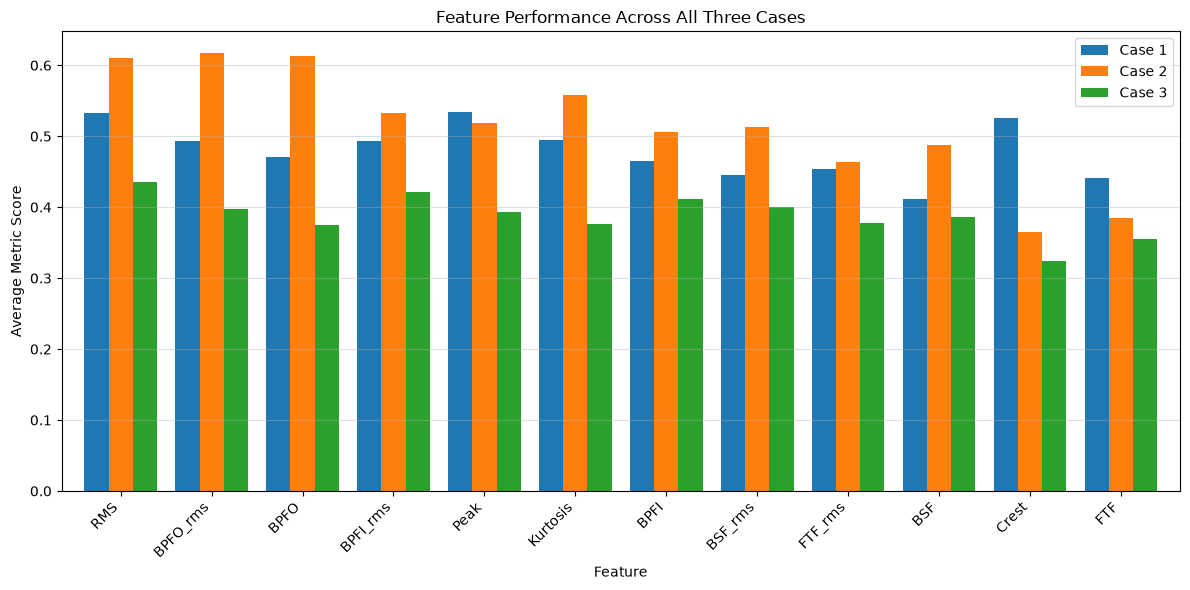

In [43]:
fig, ax = plt.subplots(figsize=(12, 6))

summary_df[list(CASES)].plot(
    kind="bar",
    ax=ax,
    width=0.8,
)

ax.set_ylabel("Average Metric Score")
ax.set_title("Feature Performance Across All Three Cases")
ax.grid(axis="y", alpha=0.4)

plt.xticks(
    rotation=45,
    ha="right",
)

plt.tight_layout()
plt.show()

# 24. Inspecting time-domain feature life curves

Before trusting the numerical ranking, it is worth looking at the actual life curves.

This plot contains the four time-domain features for all three experiments. The goal is to visually check whether the numerical scores make engineering sense.

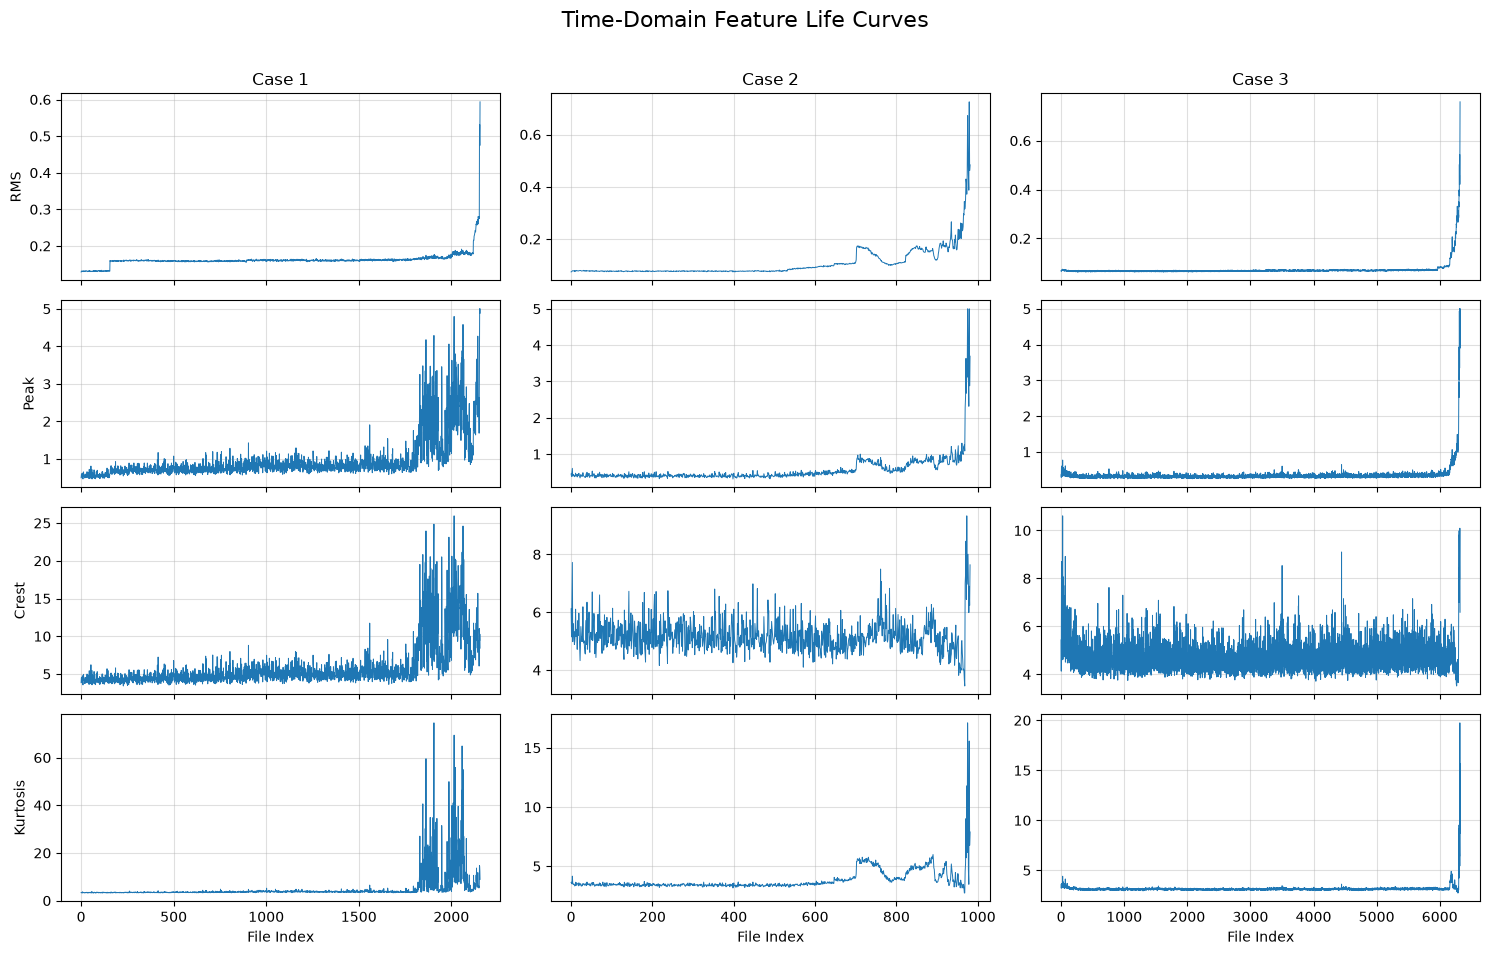

In [44]:
time_feature_names = [
    "RMS",
    "Peak",
    "Crest",
    "Kurtosis",
]

fig, axes = plt.subplots(
    len(time_feature_names),
    len(CASES),
    figsize=(15, 10),
    sharex="col",
)

for case_column, (case_name, df) in enumerate(
    frames.items()
):
    for feature_row, feature in enumerate(
        time_feature_names
    ):
        ax = axes[feature_row, case_column]

        ax.plot(
            df["file_idx"],
            df[feature],
            linewidth=0.7,
        )

        if feature_row == 0:
            ax.set_title(case_name)

        if case_column == 0:
            ax.set_ylabel(feature)

        ax.grid(alpha=0.4)

for case_column in range(len(CASES)):
    axes[-1, case_column].set_xlabel(
        "File Index"
    )

plt.suptitle(
    "Time-Domain Feature Life Curves",
    fontsize=16,
)

plt.tight_layout(
    rect=[0, 0.03, 1, 0.97]
)

plt.show()

# 25. Inspecting the fault-frequency features

The next plot focuses on BPFO, BPFI, BSF, and FTF.

The highlighted feature in each case corresponds to the documented fault type. This does not mean the other frequencies should be ignored; it simply gives us a visual reference for the frequency that physics tells us to expect.

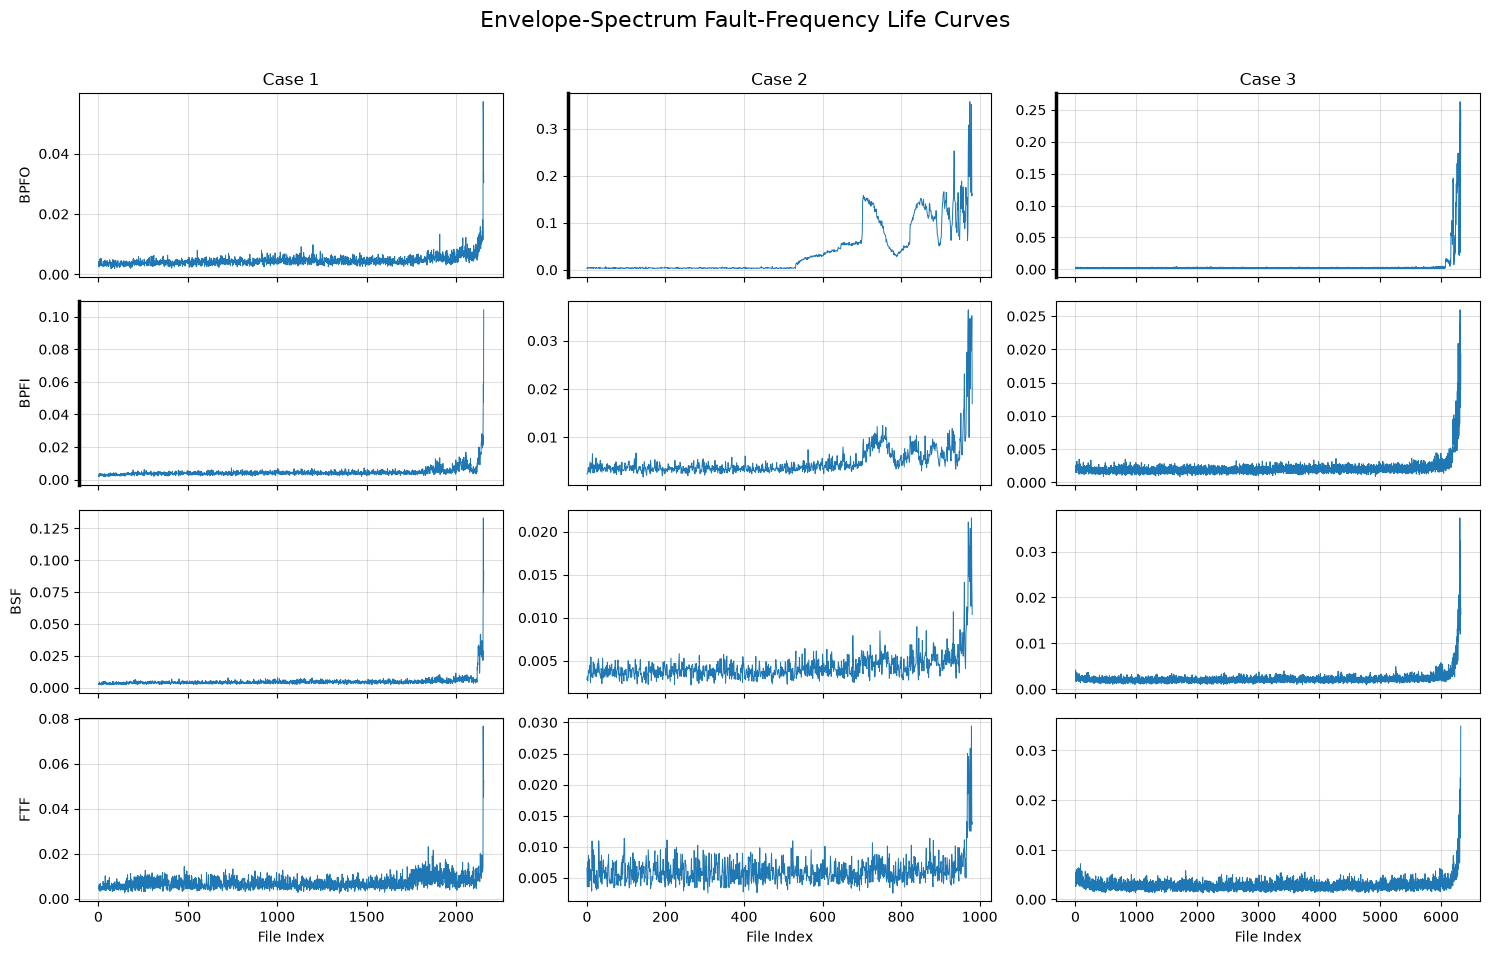

In [45]:
frequency_feature_names = [
    "BPFO",
    "BPFI",
    "BSF",
    "FTF",
]

fig, axes = plt.subplots(
    len(frequency_feature_names),
    len(CASES),
    figsize=(15, 10),
    sharex="col",
)

for case_column, (case_name, df) in enumerate(
    frames.items()
):
    expected_fault = CASES[case_name]["fault"]

    for feature_row, feature in enumerate(
        frequency_feature_names
    ):
        ax = axes[feature_row, case_column]

        ax.plot(
            df["file_idx"],
            df[feature],
            linewidth=0.7,
        )

        if feature == expected_fault:
            ax.spines["left"].set_linewidth(2.5)

        if feature_row == 0:
            ax.set_title(case_name)

        if case_column == 0:
            ax.set_ylabel(feature)

        ax.grid(alpha=0.4)

for case_column in range(len(CASES)):
    axes[-1, case_column].set_xlabel(
        "File Index"
    )

plt.suptitle(
    "Envelope-Spectrum Fault-Frequency Life Curves",
    fontsize=16,
)

plt.tight_layout(
    rect=[0, 0.03, 1, 0.97]
)

plt.show()

We can perform the same visual check for the RMS version of each frequency-domain feature.

The RMS feature is less dependent on one individual spectral line, so it can sometimes be more stable when the energy is spread across several nearby bins.

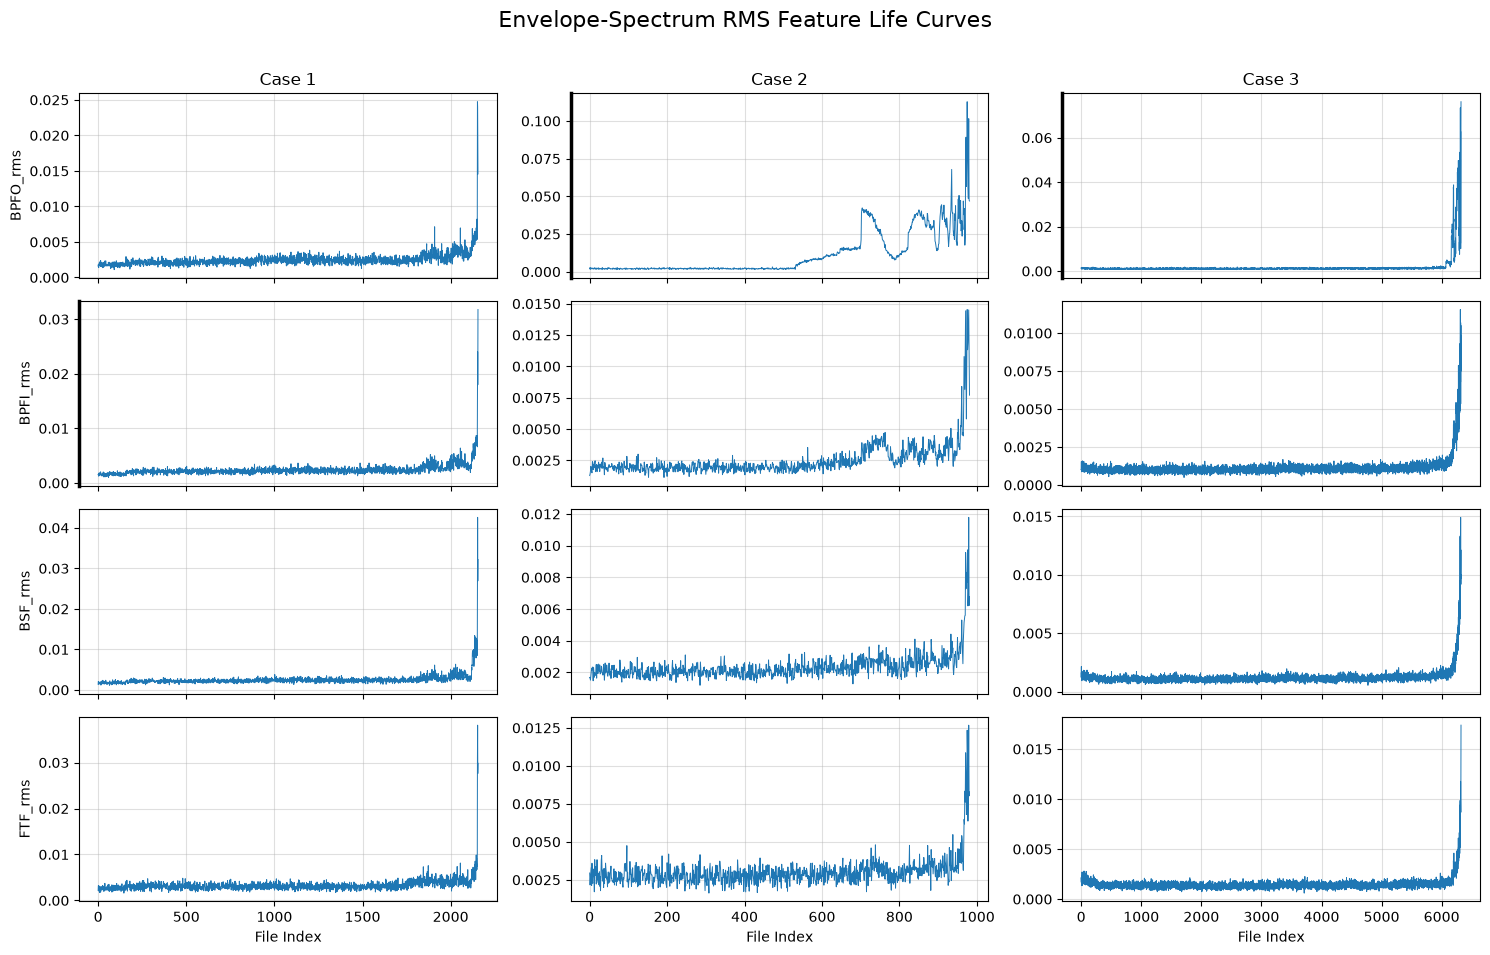

In [46]:
frequency_rms_names = [
    "BPFO_rms",
    "BPFI_rms",
    "BSF_rms",
    "FTF_rms",
]

fig, axes = plt.subplots(
    len(frequency_rms_names),
    len(CASES),
    figsize=(15, 10),
    sharex="col",
)

for case_column, (case_name, df) in enumerate(
    frames.items()
):
    expected_fault = CASES[case_name]["fault"]

    for feature_row, feature in enumerate(
        frequency_rms_names
    ):
        ax = axes[feature_row, case_column]

        ax.plot(
            df["file_idx"],
            df[feature],
            linewidth=0.7,
        )

        if (
            feature.replace("_rms", "")
            == expected_fault
        ):
            ax.spines["left"].set_linewidth(2.5)

        if feature_row == 0:
            ax.set_title(case_name)

        if case_column == 0:
            ax.set_ylabel(feature)

        ax.grid(alpha=0.4)

for case_column in range(len(CASES)):
    axes[-1, case_column].set_xlabel(
        "File Index"
    )

plt.suptitle(
    "Envelope-Spectrum RMS Feature Life Curves",
    fontsize=16,
)

plt.tight_layout(
    rect=[0, 0.03, 1, 0.97]
)

plt.show()

# 26. Peak vs. RMS around a fault frequency

Peak and RMS answer slightly different questions.

The **peak** feature reacts strongly to the single strongest spectral line in the chosen frequency band.

The **RMS** feature considers the energy distributed across the entire band.

If they are strongly correlated, they are carrying similar information. If not, the RMS feature may be capturing broader spectral changes that the single peak misses.

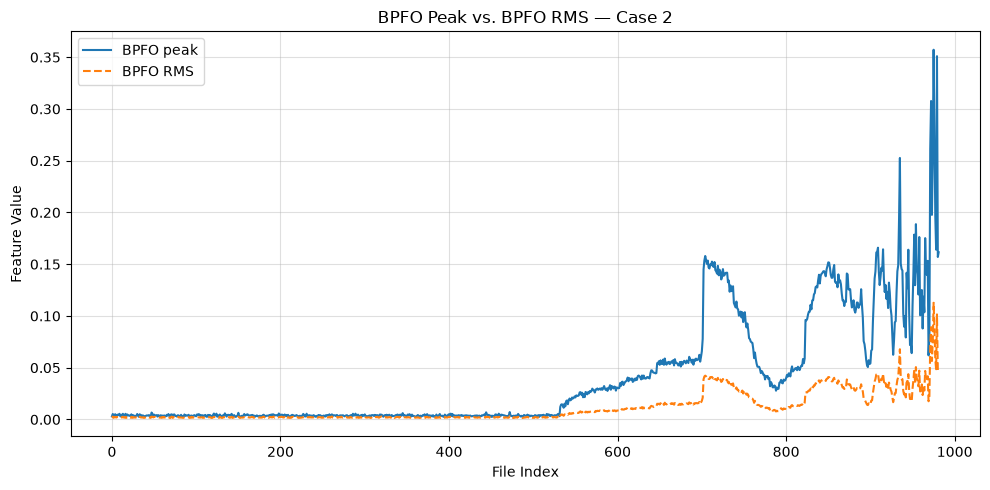

Correlation: 0.9980


In [47]:
comparison_case = "Case 2"
comparison_df = frames[comparison_case]

plt.figure(figsize=(10, 5))

plt.plot(
    comparison_df["file_idx"],
    comparison_df["BPFO"],
    label="BPFO peak",
)

plt.plot(
    comparison_df["file_idx"],
    comparison_df["BPFO_rms"],
    label="BPFO RMS",
    linestyle="--",
)

plt.title(
    f"BPFO Peak vs. BPFO RMS — {comparison_case}"
)

plt.xlabel("File Index")
plt.ylabel("Feature Value")
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

correlation = comparison_df["BPFO"].corr(
    comparison_df["BPFO_rms"]
)

print(f"Correlation: {correlation:.4f}")

# 27. Selecting a small common feature set

Using every feature in the final health index would make the model harder to interpret and could give several highly related features excessive influence.

We therefore select the top five features according to their **mean score across all three cases**.

This is a simple feature-selection step, not a claim that five is mathematically optimal. The point is to create a compact and interpretable health indicator.

In [48]:
TOP_N_FEATURES = 5

best_features = summary_df.index[
    :TOP_N_FEATURES
].tolist()

print("Selected features:")

for rank, feature in enumerate(
    best_features,
    start=1,
):
    print(f"{rank}. {feature}")

Selected features:
1. RMS
2. BPFO_rms
3. BPFO
4. BPFI_rms
5. Peak


# 28. PCA health index

We now combine the selected features into one health indicator using **Principal Component Analysis (PCA)**.

The selected features can have very different numerical scales. We therefore:

1. Apply a log transform to reduce the influence of very large values and make multiplicative changes easier to handle.
2. Standardize every feature so that each starts with comparable variance.
3. Apply PCA.
4. Use the first principal component, PC1, as the combined health index.

PCA is useful here because we are not trying to predict a labelled failure time. We are looking for a direction in feature space that captures the largest amount of shared variation.

In [49]:
pc_models = {}
pc1_health_indices = {}

for case_name, df in frames.items():
    X = df[best_features].to_numpy()

    # The selected features are non-negative, so a small
    # offset prevents log(0).
    X_log = np.log(X + 1e-9)

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_log)

    pca = PCA()
    components = pca.fit_transform(X_scaled)

    pc1 = components[:, 0]

    # PCA's sign is arbitrary. Flip it when necessary so
    # that the health index increases with time.
    if pearsonr(
        np.arange(len(pc1)),
        pc1,
    )[0] < 0:
        pc1 = -pc1

    pc_models[case_name] = {
        "scaler": scaler,
        "pca": pca,
    }

    pc1_health_indices[case_name] = pc1

    explained_variance = (
        pca.explained_variance_ratio_[0] * 100
    )

    print(
        f"{case_name}: "
        f"PC1 explains {explained_variance:.2f}% "
        f"of the selected-feature variance."
    )

Case 1: PC1 explains 76.74% of the selected-feature variance.
Case 2: PC1 explains 88.85% of the selected-feature variance.
Case 3: PC1 explains 86.39% of the selected-feature variance.


A high PC1 explained-variance percentage means that the selected features share a strong common pattern.

It does **not** by itself prove that PC1 is a good health indicator. We still need to look at how PC1 behaves over the life of each bearing.

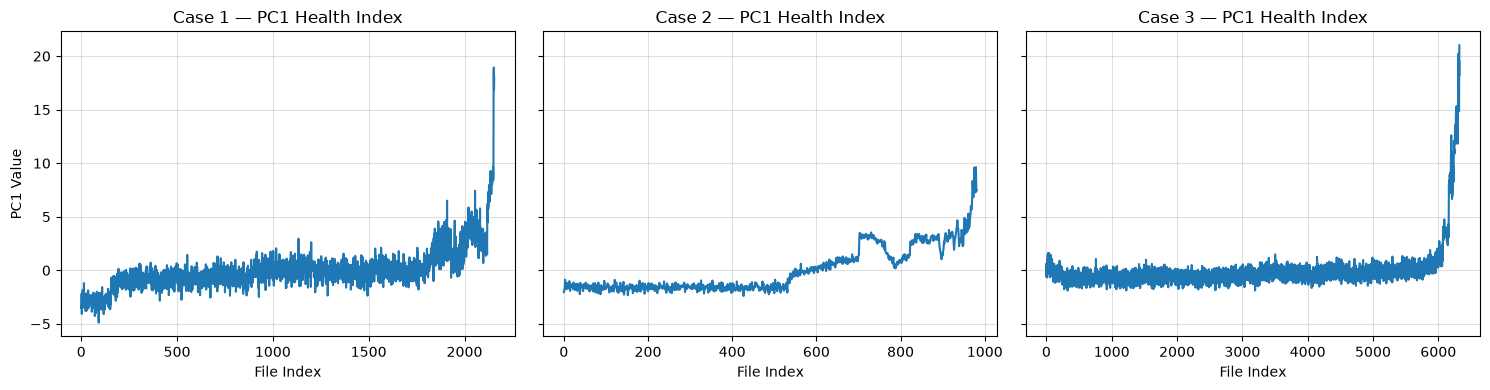

In [50]:
fig, axes = plt.subplots(
    1,
    len(CASES),
    figsize=(15, 4),
    sharey=True,
)

for axis, (case_name, df) in zip(
    axes,
    frames.items(),
):
    axis.plot(
        df["file_idx"],
        pc1_health_indices[case_name],
    )

    axis.set_title(
        f"{case_name} — PC1 Health Index"
    )
    axis.set_xlabel("File Index")
    axis.grid(alpha=0.4)

axes[0].set_ylabel("PC1 Value")

plt.tight_layout()
plt.show()

# 29. Does PCA actually improve the health indicator?

PCA gives us a combined indicator, but a more complicated method is not automatically better.

We therefore calculate the same three metrics for PC1 and compare it against the best individual feature for each case.

If PC1 scores better, it suggests that combining several features has produced a more stable degradation indicator. If a single feature wins, that is also a useful result—it means PCA was not necessary for that case.

In [51]:
comparison_rows = []

for case_name, df in frames.items():
    pc1 = pc1_health_indices[case_name]

    trend, residual = split_trend(pc1)

    pc1_monotonicity = monotonicity(trend)
    pc1_trendability = trendability(trend)
    pc1_robustness = robustness(
        pc1,
        residual,
    )

    pc1_average = np.mean([
        pc1_monotonicity,
        pc1_trendability,
        pc1_robustness,
    ])

    best_single = score_tables[
        case_name
    ].iloc[0]

    comparison_rows.append({
        "Case": case_name,
        "PC1 Monotonicity": pc1_monotonicity,
        "PC1 Trendability": pc1_trendability,
        "PC1 Robustness": pc1_robustness,
        "PC1 Average Score": pc1_average,
        "Best Single Feature": best_single["Feature"],
        "Best Single Score": best_single["Average"],
    })

pca_comparison = pd.DataFrame(
    comparison_rows
)

print("PC1 vs. Best Single Feature")
print(
    pca_comparison.round(3)
)

PC1 vs. Best Single Feature
     Case  PC1 Monotonicity  PC1 Trendability  PC1 Robustness  \
0  Case 1             0.040             0.755           0.523   
1  Case 2             0.113             0.865           0.836   
2  Case 3             0.024             0.419           0.551   

   PC1 Average Score Best Single Feature  Best Single Score  
0              0.439                Peak              0.535  
1              0.605            BPFO_rms              0.617  
2              0.331                 RMS              0.436  


The final bar chart gives a simple visual comparison between the PCA-based health index and the strongest individual feature in each case.

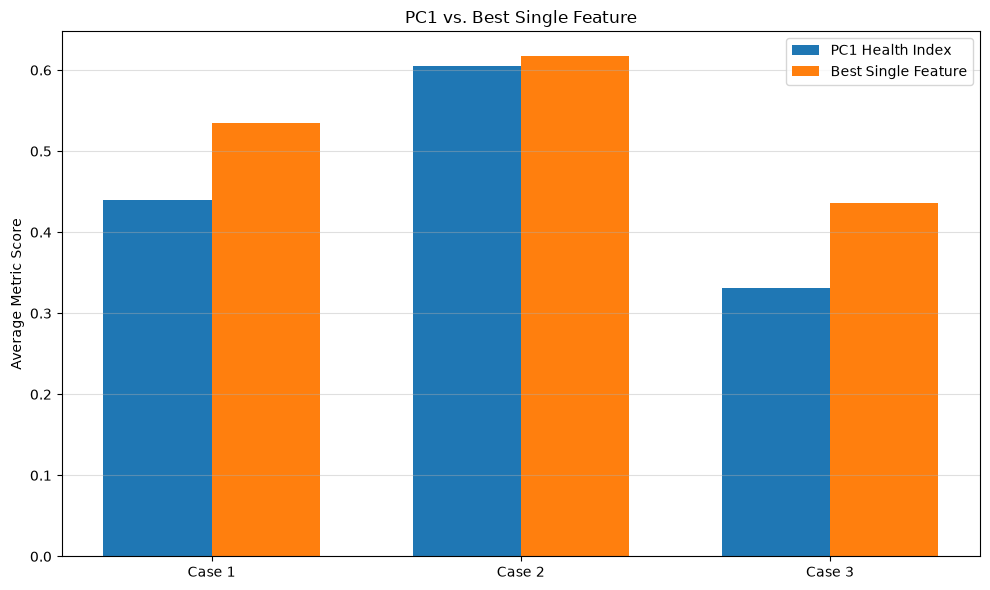

In [52]:
x_positions = np.arange(
    len(pca_comparison)
)

bar_width = 0.35

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.bar(
    x_positions - bar_width / 2,
    pca_comparison["PC1 Average Score"],
    bar_width,
    label="PC1 Health Index",
)

ax.bar(
    x_positions + bar_width / 2,
    pca_comparison["Best Single Score"],
    bar_width,
    label="Best Single Feature",
)

ax.set_ylabel("Average Metric Score")
ax.set_title(
    "PC1 vs. Best Single Feature"
)

ax.set_xticks(x_positions)
ax.set_xticklabels(
    pca_comparison["Case"]
)

ax.legend()
ax.grid(axis="y", alpha=0.4)

plt.tight_layout()
plt.show()

# Final Observations

This analysis started with raw vibration measurements and gradually turned them into features that can be used to describe the condition of a bearing.

A few things stood out during the analysis:

* The raw time-domain signal becomes noticeably different as the bearing approaches failure.
* Simple features such as RMS, peak, crest factor and kurtosis capture different aspects of the vibration signal.
* The theoretical bearing defect frequencies gave us a useful physical reference for interpreting the frequency-domain results.
* The BPFO itself was not particularly obvious in the raw spectrum. Envelope analysis made the repeating impact pattern much easier to see.
* Looking at the features across the complete run was more useful than looking at a single spectrum, because we are interested in how the bearing condition changes with time.
* Finally, PCA allowed several useful features to be combined into a single health indicator.

The main takeaway for me was that bearing condition monitoring is not just about finding a large peak in an FFT. The more useful question is **which signal characteristics consistently change as the bearing degrades?**

This analysis was a first attempt at answering that question using relatively simple signal-processing and data-analysis techniques.

### Limitations

A few things should be kept in mind when interpreting these results: the dataset contains only three bearing failure cases, the bearing speed is treated as constant when calculating the theoretical defect frequencies, and the health-index construction is based on relatively simple feature-ranking and PCA methods. Therefore, the results are useful for exploring the dataset, but shouldn't be treated as a general-purpose predictive-maintenance model.